# Признаки по скользящим окнам

**Итог.** Признаки по скользящим окнам заметного выигрыша не дают: средний logloss ниже, чем у конфигурации B, на 0,0005–0,0011 при пороге 0,003; в марте 2017 обе проверенные конфигурации лучше B.

В `10_rolling_validation.ipynb` расширенные признаки дали небольшой средний выигрыш, но качество сильно зависело от месяца, а классификатор отличал соседние месяцы по признакам почти безошибочно
(AUC 0,90–0,997). Часть признаков сдвигается по построению: накопленные счётчики истории и стаж растут вместе с календарём, потому что данные начинаются в январе 2015 года.

**Гипотеза.** Признаки по скользящим окнам фиксированной длины (30, 60, 90, 180, 365 дней перед датой прогноза, `scripts/09_features_v3.py`) устойчивее накопленных и улучшат качество по месяцам.

**Критерий, заданный до расчёта.** Конфигурация считается лучше конфигурации B (52 признака из `10_rolling_validation.ipynb`), если средний logloss по девяти тестовым месяцам ниже хотя бы на 0,003 и в марте 2017 она не хуже B.
Дополнительно считается число месяцев из девяти, в которых она лучше B.

**Конфигурации** (схема проверки та же: зазор в один месяц, все допустимые месяцы, те же параметры LightGBM и то же число деревьев 416):
- B: 52 признака. Результаты берутся из MLflow (вложенный запуск из `10_rolling_validation.ipynb`), модель заново не обучается.
- E: 40 признаков, B без накопленных признаков (стаж по регистрации и по первой транзакции, число транзакций, отмен и оплат, суммарная оплата, числа разных тарифов и способов оплаты, число смен тарифа и способа оплаты, число перерывов, число прошедших окончаний подписки).
- F: 80 признаков, E плюс признаки по пяти окнам и ограниченный стаж (не более 365 дней по первой транзакции и 730 по регистрации).

**Зависимости.** Ноутбук использует результаты `10_rolling_validation.ipynb` из MLflow: ноутбук 10 должен быть выполнен, а MLflow доступен.

In [1]:
import time

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split

P = "/workspace/data/processed/"
LABELS = P + "labels_months.parquet"
ALL_MONTHS = [f"2016-{m:02d}-01" for m in range(1, 13)] + ["2017-01-01", "2017-02-01", "2017-03-01"]
TEST_MONTHS = ALL_MONTHS[6:]  # июль 2016 .. март 2017
GAP_MONTHS = ALL_MONTHS[-3:]  # месяцы, для которых считается цена зазора
TRAIN_SHARE = 20  # процент клиентов обучающих месяцев
RARE_MIN = 200  # порог редкой категории в обучающей выборке
N_TREES = 416  # число деревьев из пилота в 10_rolling_validation.ipynb
WINDOWS = [30, 60, 90, 180, 365]
SEED = 42
INK, BLUE, ORANGE, GREEN, GRAY, PINK = "#2b2f36", "#0072B2", "#E69F00", "#009E73", "#8a8f98", "#CC79A7"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

NUM_V1 = [
    "last_plan_days", "last_list_price", "last_paid", "last_auto_renew", "last_is_cancel", "last_discount",
    "days_to_expire", "days_since_last_tx", "tenure_days", "n_tx", "n_cancel", "share_cancel", "n_paid_tx",
    "total_paid", "avg_paid", "share_zero_paid", "share_discount", "share_auto_renew", "n_plans", "n_methods",
    "n_tx_30d", "n_tx_90d", "n_plan_changes", "n_method_changes", "n_lapses", "has_profile", "age", "reg_tenure_days",
]
NUM_NEW = [
    "prev_plan_days", "prev_paid", "prev_auto_renew", "prev_is_cancel", "plan_changed", "method_changed",
    "auto_renew_changed", "days_between_last_two_tx", "ex_minus_td", "ex_minus_td_minus_plan", "paid_per_day",
    "list_per_day", "discount_ratio", "n_cancel_5", "avg_paid_5", "avg_plan_days_5", "share_auto_5", "n_expired", "lapse_share",
]
CAT_ALL = ["last_method", "city", "gender", "registered_via", "prev_method"]
METRICS = ("n_tx", "n_cancel", "n_paid_tx", "total_paid", "share_auto", "n_plan_changes", "n_method_changes", "n_lapses")
NUM_V3 = [f"{m}_{w}d" for w in WINDOWS for m in METRICS if f"{m}_{w}d" not in ("n_tx_30d", "n_tx_90d")]  # n_tx_30d и n_tx_90d уже есть в NUM_V1
CAPS = ["tenure_cap", "reg_tenure_cap"]
CUMULATIVE = [
    "tenure_days", "reg_tenure_days", "n_tx", "n_cancel", "n_paid_tx", "total_paid", "n_plans", "n_methods",
    "n_plan_changes", "n_method_changes", "n_lapses", "n_expired",
]
NUM_ALL = NUM_V1 + NUM_NEW + NUM_V3 + CAPS
FEATS_B = NUM_V1 + NUM_NEW + CAT_ALL
FEATS_E = [f for f in FEATS_B if f not in CUMULATIVE]
FEATS_F = FEATS_E + NUM_V3 + CAPS
print("признаков: B =", len(FEATS_B), " E =", len(FEATS_E), " F =", len(FEATS_F))

con = duckdb.connect()
con.execute("SET memory_limit='4GB'; SET threads=2; SET enable_progress_bar=false")

признаков: B = 52  E = 40  F = 80


## 1. Загрузка данных и подготовка признаков
Загрузка присоединяет признаки по окнам (`features_v3`) к расширенным признакам (`features_v2`) и меткам. Стаж ограничивается сверху (`tenure_cap`, `reg_tenure_cap`).
Подготовка (обрезка по квантилям, объединение редких категорий) обучается только на обучающем окне каждой конфигурации, как в `10_rolling_validation.ipynb`.
Обучающие месяцы (январь 2016 .. февраль 2017) загружаются один раз с долей клиентов `TRAIN_SHARE`.

In [2]:
def load_month(month: str, source: str, share: int | None = None) -> pd.DataFrame:
    '''Загружает признаки (v2 и v3) и метки одного месяца.

    Args:
        month (str): первый день месяца окончания подписки ('YYYY-MM-01').
        source (str): источник меток ('own' или 'official').
        share (int | None): процент клиентов по хешу `msno`; None: все клиенты.

    Returns:
        pd.DataFrame: признаки, ограниченные значения стажа и метка `is_churn`.
    '''
    cond = f"AND hash(f.msno) % 100 < {share}" if share else ""
    df = con.sql(f'''
        SELECT
            f.*,
            g.* EXCLUDE (msno, expire_month, n_tx_30d, n_tx_90d),
            l.is_churn
        FROM '{P}features_v2_{month[:7]}.parquet' f
        JOIN '{P}features_v3_{month[:7]}.parquet' g ON g.msno = f.msno AND g.expire_month = f.expire_month
        JOIN '{LABELS}' l ON l.msno = f.msno AND l.expire_month = f.expire_month
        WHERE l.source = '{source}'
            {cond}
    ''').df()
    df["tenure_cap"] = df["tenure_days"].astype("float32").clip(upper=365)
    df["reg_tenure_cap"] = df["reg_tenure_days"].astype("float32").clip(upper=730)
    return df


def label_source(month: str) -> str:
    '''Возвращает источник меток для месяца: официальные для февраля и марта 2017, иначе собственные.

    Args:
        month (str): первый день месяца ('YYYY-MM-01').

    Returns:
        str: 'official' или 'own'.
    '''
    return "official" if month >= "2017-02-01" else "own"


t0 = time.time()
train_pool = {m: load_month(m, label_source(m), TRAIN_SHARE) for m in ALL_MONTHS[:14]}  # до февраля 2017 включительно
print({m[:7]: len(d) for m, d in train_pool.items()}, "время, с:", round(time.time() - t0))

{'2016-01': 151929, '2016-02': 139155, '2016-03': 161688, '2016-04': 146297, '2016-05': 147766, '2016-06': 148588, '2016-07': 153267, '2016-08': 159787, '2016-09': 168545, '2016-10': 166941, '2016-11': 177927, '2016-12': 175913, '2017-01': 173536, '2017-02': 198643} время, с: 31


In [3]:
def fit_prep(train: pd.DataFrame) -> dict:
    '''Обучает преобразования признаков на обучающих строках.

    Args:
        train (pd.DataFrame): обучающая выборка.

    Returns:
        dict: границы обрезки (`lo`, `hi`) и множества частых категорий (`frequent`).
    '''
    num = train[NUM_ALL].astype("float32")
    frequent = {}
    for c in CAT_ALL:
        counts = train[c].astype("string").fillna("missing").value_counts()
        frequent[c] = set(counts[counts >= RARE_MIN].index) | {"missing"}
    return {"lo": num.quantile(0.001), "hi": num.quantile(0.999), "frequent": frequent}


def apply_prep(df: pd.DataFrame, prep: dict) -> pd.DataFrame:
    '''Применяет обученные преобразования.

    Args:
        df (pd.DataFrame): строки таблицы признаков.
        prep (dict): результат `fit_prep`.

    Returns:
        pd.DataFrame: числовые признаки (float32, обрезанные) и категориальные (тип category).
    '''
    X = df[NUM_ALL].astype("float32").clip(lower=prep["lo"], upper=prep["hi"], axis=1)
    for c in CAT_ALL:
        s = df[c].astype("string").fillna("missing")
        X[c] = pd.Categorical(s.where(s.isin(prep["frequent"][c]), "other"), categories=sorted(prep["frequent"][c] | {"other"}))
    return X


def evaluate(y_true: np.ndarray, p: np.ndarray) -> dict:
    '''Считает метрики качества вероятностей оттока.

    Args:
        y_true (np.ndarray): фактические метки (1: отток).
        p (np.ndarray): предсказанные вероятности оттока.

    Returns:
        dict: logloss, pr_auc, roc_auc, среднее предсказание и фактическая доля оттока.
    '''
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {
        "logloss": log_loss(y_true, p), "pr_auc": average_precision_score(y_true, p), "roc_auc": roc_auc_score(y_true, p),
        "mean_pred": float(p.mean()), "actual_rate": float(y_true.mean()),
    }


def months_before(month: str, gap: int = 1) -> list:
    '''Возвращает обучающие месяцы для прогноза месяца `month`.

    Args:
        month (str): тестовый месяц ('YYYY-MM-01').
        gap (int): зазор в месяцах: 1, обучение до месяца T−2; 0, до месяца T−1.

    Returns:
        list: допустимые месяцы.
    '''
    return ALL_MONTHS[: ALL_MONTHS.index(month) - gap]

## 2. Результаты конфигурации B из MLflow
Метрики модели B по месяцам берутся из вложенного запуска `B: 52 признака, все месяцы` (история метрик по шагам = тестовые месяцы по порядку).

In [4]:
mlflow.set_tracking_uri("http://mlflow:5000")
EXPERIMENT = "churn_model"
mlflow.set_experiment(EXPERIMENT)
client = mlflow.tracking.MlflowClient()
run_b = mlflow.search_runs(
    experiment_names=[EXPERIMENT], filter_string="tags.mlflow.runName = 'B: 52 признака, все месяцы'",
    order_by=["start_time DESC"], max_results=1, output_format="list",
)[0]
b_rows = []
hist = {k: [m.value for m in sorted(client.get_metric_history(run_b.info.run_id, k), key=lambda m: m.step)] for k in ["logloss", "pr_auc", "roc_auc", "mean_pred", "actual_rate"]}
for i, month in enumerate(TEST_MONTHS):
    b_rows.append({"month": month[:7], "config": "B: 52 признака", **{k: v[i] for k, v in hist.items()}})
res_b = pd.DataFrame(b_rows)
print("запуск B:", run_b.info.run_id, " месяцев:", len(res_b))
res_b[["month", "logloss", "pr_auc", "roc_auc"]].round(4)

запуск B: 6a4957481aff42dc8fcc87f97a3a1448  месяцев: 9


,month,logloss,pr_auc,roc_auc
0,2016-07,0.1196,0.5412,0.9355
1,2016-08,0.1246,0.3455,0.9083
2,2016-09,0.1552,0.5430,0.9254
3,2016-10,0.1074,0.3999,0.8991
4,2016-11,0.1082,0.8579,0.9612
5,2016-12,0.2302,0.6114,0.7529
6,2017-01,0.1189,0.4842,0.8850
7,2017-02,0.1747,0.4586,0.8433
8,2017-03,0.2521,0.4363,0.8133


## 3. Скользящая проверка конфигураций E и F
Для каждого тестового месяца: обучение конфигураций E и F на допустимых месяцах с зазором, оценка на всём месяце. Для трёх последних месяцев дополнительно обучается модель B без зазора (результаты в разделе 6).

In [5]:
PARAMS = {
    "learning_rate": 0.05, "num_leaves": 63, "min_child_samples": 100, "subsample": 0.8, "subsample_freq": 1,
    "colsample_bytree": 0.8, "reg_lambda": 1.0, "random_state": SEED, "n_jobs": 6, "verbose": -1,
}
CONFIGS = {
    "E: без накопленных": (FEATS_E, 1),
    "F: E и признаки по окнам": (FEATS_F, 1),
    "B без зазора": (FEATS_B, 0),
}

rows = []
for month in TEST_MONTHS:
    t0 = time.time()
    test = load_month(month, label_source(month))
    y_test = test.is_churn.to_numpy()
    for name, (feats, gap) in CONFIGS.items():
        if gap == 0 and month not in GAP_MONTHS:
            continue
        train = pd.concat([train_pool[m] for m in months_before(month, gap)])
        prep = fit_prep(train)
        clf = lgb.LGBMClassifier(n_estimators=N_TREES, **PARAMS).fit(apply_prep(train, prep)[feats], train.is_churn.to_numpy())
        p = clf.predict_proba(apply_prep(test, prep)[feats])[:, 1]
        rows.append({"month": month[:7], "config": name, "n_train": len(train), **evaluate(y_test, p)})
        del train, clf
    print(month[:7], "готово, время, с:", round(time.time() - t0))
    del test

res = pd.DataFrame(rows)
all_res = pd.concat([res_b, res[~res.config.str.startswith("B без")]])
all_res.pivot(index="month", columns="config", values="logloss").round(4)

2016-07 готово, время, с: 74


2016-08 готово, время, с: 83


2016-09 готово, время, с: 113


2016-10 готово, время, с: 121


2016-11 готово, время, с: 119


2016-12 готово, время, с: 139


2017-01 готово, время, с: 199


2017-02 готово, время, с: 217


2017-03 готово, время, с: 264


config,B: 52 признака,E: без накопленных,F: E и признаки по окнам
month,,,
2016-07,0.1196,0.1209,0.1192
2016-08,0.1246,0.1215,0.1257
2016-09,0.1552,0.1435,0.1581
2016-10,0.1074,0.1076,0.1073
2016-11,0.1082,0.1109,0.1095
2016-12,0.2302,0.2303,0.2308
2017-01,0.1189,0.1220,0.1186
2017-02,0.1747,0.1769,0.1735
2017-03,0.2521,0.2476,0.2436


## 4. Проверка гипотезы по критерию
Для E и F: средняя разность logloss относительно B по девяти месяцам (отрицательная означает улучшение), число месяцев, в которых конфигурация лучше B, разность в марте и вывод по критерию
(средняя разность не больше −0,003 и март не хуже B).

In [6]:
b = res_b.set_index("month")
rows_cmp = {}
for name in ["E: без накопленных", "F: E и признаки по окнам"]:
    g = res[res.config == name].set_index("month")
    d_ll, d_pr = g.logloss - b.logloss, g.pr_auc - b.pr_auc
    rows_cmp[name] = {
        "ср. logloss": g.logloss.mean(), "ср. разность logloss к B": d_ll.mean(), "месяцев лучше B (logloss)": int((d_ll < 0).sum()),
        "ср. PR-AUC": g.pr_auc.mean(), "ср. разность PR-AUC к B": d_pr.mean(),
        "март: разность logloss к B": d_ll["2017-03"], "март: разность PR-AUC к B": d_pr["2017-03"],
        "критерий выполнен": bool(d_ll.mean() <= -0.003 and d_ll["2017-03"] <= 0),
    }
rows_cmp["B (эталон)"] = {"ср. logloss": b.logloss.mean(), "ср. PR-AUC": b.pr_auc.mean()}
pd.DataFrame(rows_cmp).T.round(4)

,ср. logloss,ср. разность logloss к B,месяцев лучше B (logloss),ср. PR-AUC,ср. разность PR-AUC к B,март: разность logloss к B,март: разность PR-AUC к B,критерий выполнен
E: без накопленных,0.153469,-0.00109,3,0.522808,0.003025,-0.004479,0.025425,False
F: E и признаки по окнам,0.154026,-0.000533,5,0.525318,0.005535,-0.008451,0.042287,False
B (эталон),0.154559,NaN,NaN,0.519783,NaN,NaN,NaN,NaN


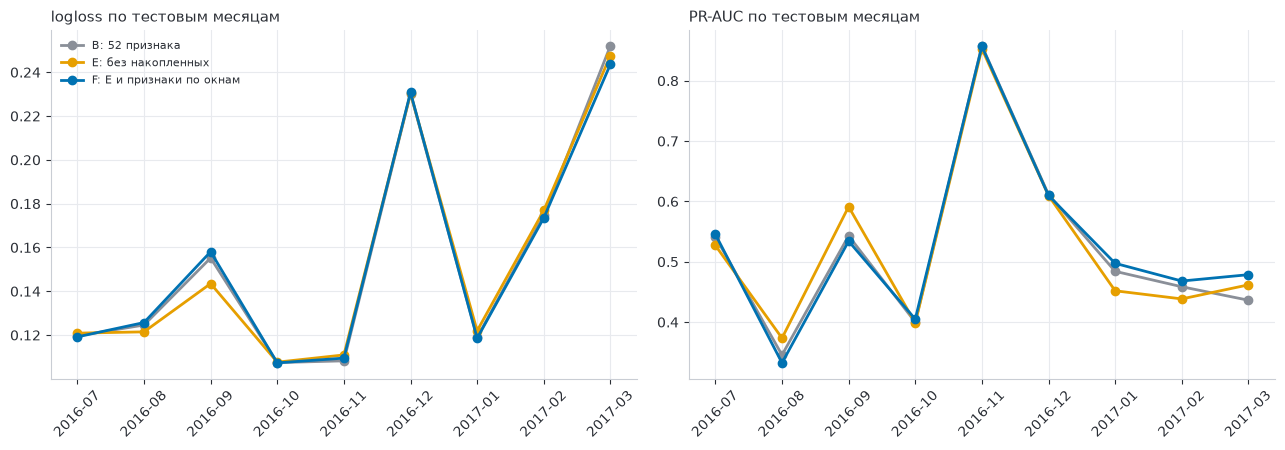

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
series = [("B: 52 признака", b.reset_index(), GRAY), ("E: без накопленных", res[res.config == "E: без накопленных"], ORANGE), ("F: E и признаки по окнам", res[res.config == "F: E и признаки по окнам"], BLUE)]
for metric, ax, title in [("logloss", axes[0], "logloss по тестовым месяцам"), ("pr_auc", axes[1], "PR-AUC по тестовым месяцам")]:
    for name, g, color in series:
        ax.plot(g.month, g[metric], color=color, marker="o", lw=2, label=name)
    ax.set_title(title, loc="left", fontsize=11)
    ax.tick_params(axis="x", labelrotation=45)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig_windows = fig
plt.show()

## 5. Диагностика сдвига для наборов B, E и F
Классификатор (LightGBM, 100 деревьев) учится отличать клиентов месяца T−2 от клиентов месяца T (по 30 тысяч клиентов, отложенные 30% для оценки).
Показан AUC для трёх наборов признаков: чем ниже, тем устойчивее набор по месяцам.

In [9]:
adv_rows = []
for month in TEST_MONTHS:
    m0 = ALL_MONTHS[ALL_MONTHS.index(month) - 2]
    a = load_month(m0, label_source(m0), 8).head(30000)
    c = load_month(month, label_source(month), 8).head(30000)
    both = pd.concat([a, c])
    prep = fit_prep(both)
    X = apply_prep(both, prep)
    z = np.r_[np.zeros(len(a)), np.ones(len(c))]
    i_tr, i_te = train_test_split(np.arange(len(both)), test_size=0.3, stratify=z, random_state=SEED)
    row = {"месяц": month[:7]}
    for name, feats in [("B", FEATS_B), ("E", FEATS_E), ("F", FEATS_F)]:
        clf = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.1, num_leaves=31, random_state=SEED, n_jobs=6, verbose=-1).fit(X.iloc[i_tr][feats], z[i_tr])
        row[f"AUC {name}"] = round(roc_auc_score(z[i_te], clf.predict_proba(X.iloc[i_te][feats])[:, 1]), 3)
        if name == "F":
            imp = pd.Series(clf.booster_.feature_importance(importance_type="gain"), index=feats).sort_values(ascending=False)
            row["главные признаки (F)"] = ", ".join(imp.index[:3])
    adv_rows.append(row)
adv = pd.DataFrame(adv_rows)
adv

,месяц,AUC B,AUC E,AUC F,главные признаки (F)
0,2016-07,0.923,0.758,0.906,"n_plan_changes_365d, tenure_cap, total_paid_365d"
1,2016-08,0.925,0.769,0.877,"days_to_expire, n_plan_changes_365d, share_cancel"
2,2016-09,0.994,0.974,0.979,"ex_minus_td, days_to_expire, prev_method"
3,2016-10,0.995,0.992,0.993,"days_between_last_two_tx, days_since_last_tx, ..."
4,2016-11,0.992,0.985,0.989,"days_between_last_two_tx, ex_minus_td_minus_pl..."
5,2016-12,0.897,0.731,0.806,"share_cancel, last_method, lapse_share"
6,2017-01,0.901,0.755,0.817,"days_to_expire, days_since_last_tx, share_cancel"
7,2017-02,0.997,0.984,0.987,"ex_minus_td_minus_plan, days_since_last_tx, da..."
8,2017-03,0.997,0.995,0.996,"ex_minus_td_minus_plan, total_paid_30d, last_a..."


## 6. Ограничение: состав клиентов в обучающих месяцах
Собственная разметка (месяцы до января 2017) считает кандидатами клиентов, у которых подписка по последней транзакции заканчивается в самом месяце. В официальных метках февраля 2017 есть ещё клиенты с датой окончания вне месяца
(вторая таблица ниже). Чтобы оценить влияние на результат, модель B для трёх последних месяцев дополнительно обучена без зазора (на месяцах до T−1; для марта в обучение входит февраль с официальными метками).
Первая таблица сравнивает её с моделью B с зазором, вторая показывает состав клиентов февраля 2017. Это справочный материал: причина различия в наборах не исследовалась.

In [8]:
gap_cmp = res[res.config == "B без зазора"].set_index("month")[["logloss", "pr_auc", "roc_auc", "mean_pred", "actual_rate"]].add_suffix(" (без зазора)")
gap_cmp = b.loc[gap_cmp.index, ["logloss", "pr_auc", "roc_auc", "mean_pred"]].add_suffix(" (с зазором)").join(gap_cmp)
gap_cmp["Δ logloss (без − с зазором)"] = gap_cmp["logloss (без зазора)"] - gap_cmp["logloss (с зазором)"]
gap_cmp["Δ PR-AUC (без − с зазором)"] = gap_cmp["pr_auc (без зазора)"] - gap_cmp["pr_auc (с зазором)"]
gap_cmp[["logloss (с зазором)", "logloss (без зазора)", "Δ logloss (без − с зазором)", "pr_auc (с зазором)", "pr_auc (без зазора)", "Δ PR-AUC (без − с зазором)", "mean_pred (с зазором)", "mean_pred (без зазора)", "actual_rate (без зазора)"]].round(4)

,logloss (с зазором),logloss (без зазора),Δ logloss (без − с зазором),pr_auc (с зазором),pr_auc (без зазора),Δ PR-AUC (без − с зазором),mean_pred (с зазором),mean_pred (без зазора),actual_rate (без зазора)
month,,,,,,,,,
2017-01,0.1189,0.1205,0.0016,0.4842,0.4644,-0.0198,0.0430,0.0448,0.0451
2017-02,0.1747,0.1717,-0.0030,0.4586,0.4715,0.0128,0.0522,0.0488,0.0639
2017-03,0.2521,0.2169,-0.0351,0.4363,0.5624,0.1261,0.0626,0.0608,0.0899


In [ ]:
con.sql(f'''
    WITH o AS (
        SELECT msno, is_churn
        FROM '{LABELS}'
        WHERE expire_month = DATE '2017-02-01' AND source = 'official'
    ),
    w AS (
        SELECT msno
        FROM '{LABELS}'
        WHERE expire_month = DATE '2017-02-01' AND source = 'own'
    ),
    f AS (
        SELECT msno, days_to_expire
        FROM '{P}features_v2_2017-02.parquet'
    )
    SELECT
        CASE WHEN w.msno IS NULL THEN 'только официальные' ELSE 'есть в обеих' END AS grp,
        count(*) AS clients,
        round(100 * avg(o.is_churn), 1) AS churn_pct,
        round(100 * avg((f.days_to_expire < 0)::INT), 1) AS expire_before_month_pct,
        round(100 * avg((f.days_to_expire BETWEEN 0 AND 27)::INT), 1) AS expire_in_month_pct,
        round(100 * avg((f.days_to_expire > 27)::INT), 1) AS expire_after_month_pct
    FROM o
    LEFT JOIN w USING (msno)
    LEFT JOIN f USING (msno)
    GROUP BY 1
    ORDER BY 1
''').df()

               grp  clients  churn_pct  expire_before_month_pct  expire_in_month_pct  expire_after_month_pct
      есть в обеих   879478        5.5                      0.0                100.0                     0.0
только официальные   113453       13.0                     16.6                  0.0                    83.4


## 7. Запись в MLflow
Родительский запуск `stable_features` с вложенными запусками для E, F и B без зазора: параметры, метрики по месяцам (шаги), средние значения, сравнение с B, графики.

In [10]:
with mlflow.start_run(run_name="stable_features"):
    mlflow.log_params({"train_share_pct": TRAIN_SHARE, "n_trees": N_TREES, "windows": "30,60,90,180,365", "baseline_run": run_b.info.run_id})
    mlflow.set_tag("stage", "stable_features")
    mlflow.log_figure(fig_windows, "windows_vs_baseline.png")
    adv.to_csv("/tmp/adversarial_auc_v3.csv", index=False)
    mlflow.log_artifact("/tmp/adversarial_auc_v3.csv")
    for name, (feats, gap) in CONFIGS.items():
        g = res[res.config == name].reset_index(drop=True)
        with mlflow.start_run(run_name=name, nested=True):
            mlflow.log_params({"n_features": len(feats), "gap_months": gap, "n_trees": N_TREES})
            for step, r in g.iterrows():
                mlflow.log_metrics({"logloss": r.logloss, "pr_auc": r.pr_auc, "roc_auc": r.roc_auc, "mean_pred": r.mean_pred, "actual_rate": r.actual_rate}, step=step)
            mlflow.log_metrics({"mean_logloss": g.logloss.mean(), "mean_pr_auc": g.pr_auc.mean(), "march_logloss": g.logloss.iloc[-1], "march_pr_auc": g.pr_auc.iloc[-1]})
print("записано в MLflow, интерфейс: http://localhost:5001")

2026/10/28 12:14:44 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/28 12:14:44 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git branch is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/28 12:14:44 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git repository URL is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



🏃 View run E: без накопленных at: http://mlflow:5000/#/experiments/1/runs/3cd6acc98b6b4fc6b54bfc588541398e
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run F: E и признаки по окнам at: http://mlflow:5000/#/experiments/1/runs/6777901b04854472a4a6b43161e08916
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run B без зазора at: http://mlflow:5000/#/experiments/1/runs/9831ad017da44bbc93dec42a7ddc4dfb
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run stable_features at: http://mlflow:5000/#/experiments/1/runs/7a6b99b3bd6e45b382649b27319f518b
🧪 View experiment at: http://mlflow:5000/#/experiments/1


записано в MLflow, интерфейс: http://localhost:5001


## Выводы
- **Гипотеза по критерию не подтверждена.** Конфигурация E (без накопленных признаков): средняя разность logloss к B −0,0011 (лучше B в трёх месяцах из девяти), PR-AUC +0,003. Конфигурация F (E и признаки по окнам): −0,0005 (лучше B в пяти из девяти), PR-AUC +0,006. В марте 2017 обе лучше B: logloss −0,0045 (E) и −0,0085 (F), PR-AUC +0,025 и +0,042. Средний выигрыш мал по сравнению с изменчивостью между месяцами, март один из девяти.
- **Накопленные признаки объясняют только часть сдвига.** AUC классификатора «месяц T−2 или месяц T» заметно снижается после их удаления (июль 2016: с 0,923 до 0,758, декабрь 2016: с 0,897 до 0,731, январь 2017: с 0,901 до 0,755), но в сентябре–ноябре 2016, феврале и марте 2017 остаётся 0,97–0,995 для всех наборов. В эти месяцы различия определяют признаки календарного положения подписки (`ex_minus_td_minus_plan`, `days_to_expire`, `days_between_last_two_tx`, `days_since_last_tx`), которые нельзя убрать без потери информативности.
- **Состав клиентов в обучающих месяцах.** Без зазора logloss в январе 2017 0,1205 против 0,1189 с зазором, в феврале 0,1717 против 0,1747, в марте 0,2169 против 0,2521 (PR-AUC 0,562 против 0,436). Большое различие в марте, вероятно, связано с составом клиентов: в официальных метках февраля 2017 есть ещё 113 453 клиента (около 11%) с датой окончания подписки вне месяца, их отток 13,0% против 5,5% у общих клиентов, а в собственной разметке таких клиентов нет, и когда в обучение попадает февраль с официальными метками, качество в марте резко растёт. Оценка отдельно на клиентах с окончанием внутри месяца не выполнялась.
- **Ограничения.** Каждая конфигурация обучена один раз; число деревьев (416) подобрано на декабре 2016 для набора B и не пересматривалось для E и F; различие между E и F мало; сравнение без зазора выполнено на трёх месяцах.